In [ ]:
import json, os
import marimo as mo
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# modal_results/ = what `modal run modal_pilot.py::fetch` downloads from the volume
RES = os.path.join(os.path.dirname(os.path.abspath(__file__)), "modal_results")
FIGS = os.path.join(RES, "showcase_figures")  # every figure below is also saved here as PNG
C_PLAIN, C_GUIDED, C_ADAPT, C_DEP, C_ENV, INK2 = "#2a78d6", "#eb6834", "#1baf7a", "#52514e", "#e4e3df", "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#b5b4ae",
                     "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "font.size": 9})

# Does a negative-stain envelope make Boltz-2 more accurate?

Each map was predicted twice with Boltz-2 from sequence alone: **plain**, and **envelope-guided** (every
diffusion step nudged toward the ~20 Å negative-stain envelope). Accuracy is the TM-score against the
deposited model (0–1, higher is better; above 0.5 means the same overall fold/arrangement). Each mode's
representative model is the one Boltz is most confident in, the one you would pick without knowing the answer.

In [ ]:
_summary = os.path.join(RES, "analysis", "summary.json")
mo.stop(not os.path.exists(_summary), mo.callout(mo.md(
    f"No analysis found at `{_summary}`. Run `modal run modal_pilot.py::fetch` (after the pilot and "
    "analysis have finished) from this folder."), kind="warn"))
S = json.load(open(_summary))
BASE, GUIDED, ADAPT = S["base"], S["guided"], S.get("adaptive")  # ADAPT: confidence-aware run, if analysed
# the 13-map dataset; other maps that may be on the volume are left out of every table and figure
MAPS13 = {"EMD-1495", "EMD-6339", "EMD-1777", "EMD-25708", "EMD-40983", "EMD-1149", "EMD-2281", "EMD-5755",
          "EMD-7013", "EMD-15486", "EMD-8235", "EMD-2355", "EMD-2712"}
maps = {m["emdb"]: m for m in S["maps"] if m["emdb"] in MAPS13}
scores = pd.read_csv(os.path.join(RES, "scores.csv"))
scores = scores[scores.emdb.isin(MAPS13)]

In [ ]:
# Figure builders, shared by the display cells and the save-all cell.
MODE_STYLE = {BASE: (C_PLAIN, "o", "plain"), GUIDED: (C_GUIDED, "^", "envelope-guided")}
ADAPT_STYLE = (C_ADAPT, "s", "confidence-aware guidance")

def fig_overview():
    """Every sample (small) and the top-confidence model (large) per map; arrow plain -> guided;
    square = confidence-aware guidance (guidance scaled down when plain Boltz is confident)."""
    order = sorted(maps, key=lambda e: maps[e]["delta_tm_top_conf"])
    has_adapt = ADAPT is not None and any(ADAPT in maps[e] for e in order)
    fig, a = plt.subplots(figsize=(8.6 if has_adapt else 8, 0.8 * len(order) + 1.5))
    for i, e in enumerate(order):
        for k, (mode, (col, mk, lab)) in enumerate(MODE_STYLE.items()):
            d = scores[(scores.emdb == e) & (scores.run == mode)]
            y = i + (0.12 if k else -0.12)
            a.scatter(d.tm_ref, [y] * len(d), s=18, marker=mk, color=col, alpha=0.35, linewidths=0, zorder=2)
            a.scatter([maps[e][mode]["tm_top_conf"]], [y], s=90, marker=mk, color=col, edgecolors="white",
                      linewidths=2, zorder=4, label=f"{lab}: top-confidence model" if i == 0 else None)
        x0, x1 = maps[e][BASE]["tm_top_conf"], maps[e][GUIDED]["tm_top_conf"]
        a.annotate("", xy=(x1, i + 0.12), xytext=(x0, i - 0.12), zorder=3,
                   arrowprops=dict(arrowstyle="->", color="#8a8984", lw=1.2, shrinkA=6, shrinkB=6))
        a.text(1.03, i, f"{x1 - x0:+.2f}", va="center", fontsize=10, color="#0b0b0b",
               fontweight="bold" if abs(x1 - x0) > 0.02 else "normal")
        if has_adapt and ADAPT in maps[e]:
            xa = maps[e][ADAPT]["tm_top_conf"]
            a.scatter([xa], [i + 0.34], s=70, marker=ADAPT_STYLE[1], color=C_ADAPT, edgecolors="white",
                      linewidths=2, zorder=5, label=f"{ADAPT_STYLE[2]}: top-confidence model" if i == 0 else None)
            a.text(1.16, i, f"{xa - x0:+.2f}", va="center", fontsize=10, color="#0b0b0b",
                   fontweight="bold" if abs(xa - x0) > 0.02 else "normal")
    a.set_yticks(range(len(order)))
    a.set_yticklabels([f"{e}\n{maps[e]['pdb']}, {maps[e]['chains']} chains" for e in order], fontsize=8)
    a.set_xlim(0, 1.0); a.set_ylim(-0.6, len(order) - 0.4 + (0.2 if has_adapt else 0))
    a.axvline(0.5, color="#b5b4ae", lw=0.8, ls=":")
    a.set_xlabel("TM-score vs deposited model (higher is better)")
    top = len(order) - 0.45 + (0.2 if has_adapt else 0)
    a.text(1.03, top, "Δ guided", fontsize=8, color="#52514e")
    if has_adapt:
        a.text(1.16, top, "Δ conf-aware", fontsize=8, color="#52514e")
    a.legend(frameon=False, fontsize=8, loc="upper left", bbox_to_anchor=(0, -0.13), ncol=3 if has_adapt else 2)
    a.set_title("Envelope guidance vs plain Boltz-2 (small marks: every sample)", loc="left", fontsize=10,
                pad=12)
    fig.tight_layout()
    return fig

def fig_adaptive():
    """Plain vs confidence-aware guidance only: one arrow per map from the plain top model to the
    confidence-aware top model. Right = more accurate; solid arrow = change > 0.05 TM, dashed = smaller."""
    if ADAPT is None:
        return None
    order = sorted((e for e in maps if ADAPT in maps[e]), key=lambda e: maps[e][ADAPT]["tm_top_conf"]
                   - maps[e][BASE]["tm_top_conf"])
    fig, a = plt.subplots(figsize=(9, 0.62 * len(order) + 1.6))
    for i, e in enumerate(order):
        x0, x1 = maps[e][BASE]["tm_top_conf"], maps[e][ADAPT]["tm_top_conf"]
        d = x1 - x0
        big = abs(d) > 0.02
        long = abs(d) > 0.05  # long enough for a visible arrow; shorter: offset so neither marker hides
        y0, y1 = (i, i) if long else (i - 0.12, i + 0.12)
        if long:
            a.annotate("", xy=(x1, y1), xytext=(x0, y0), zorder=3, arrowprops=dict(
                arrowstyle="-|>,head_width=0.35,head_length=0.7", color="#3d3d3a", lw=1.8, shrinkA=7, shrinkB=7))
        else:
            a.plot([x0, x1], [y0, y1], color="#b5b4ae", lw=1.2, ls="--", zorder=3)
        a.scatter([x0], [y0], s=110, marker="o", color=C_PLAIN, edgecolors="white", linewidths=2, zorder=4,
                  label="plain Boltz-2" if i == 0 else None)
        a.scatter([x1], [y1], s=100, marker="s", color=C_ADAPT, edgecolors="white", linewidths=2, zorder=5,
                  label="confidence-aware envelope guidance" if i == 0 else None)
        word = "improved" if d > 0.02 else "worse" if d < -0.02 else "unchanged"
        glyph = "▲" if d > 0.02 else "▼" if d < -0.02 else "="
        a.text(1.03, i, f"{glyph} {d:+.2f}  {word}", va="center", fontsize=10, color="#0b0b0b",
               fontweight="bold" if big else "normal")
        p = maps[e].get("adaptive_plan")
        if p:
            a.text(1.03, i - 0.3, f"plain ipTM {p['plain_iptm']:.2f} → guidance {p['strength']:.0%}",
                   va="center", fontsize=7.5, color="#52514e")
    a.set_yticks(range(len(order)))
    a.set_yticklabels([f"{e}\n{maps[e]['pdb']}, {maps[e]['chains']} chains" for e in order], fontsize=8)
    a.set_xlim(0, 1.0); a.set_ylim(-0.7, len(order) - 0.4)
    a.axvline(0.5, color="#b5b4ae", lw=0.8, ls=":")
    a.set_xlabel("TM-score vs deposited model (higher is better)")
    dm = np.mean([maps[e][ADAPT]["tm_top_conf"] - maps[e][BASE]["tm_top_conf"] for e in order])
    a.set_title(f"Confidence-aware envelope guidance vs plain Boltz-2 ({len(order)} maps, mean Δ TM {dm:+.2f})",
                loc="left", fontsize=10, pad=12)
    a.legend(frameon=False, fontsize=8, loc="upper left", bbox_to_anchor=(0, -0.13), ncol=2)
    fig.tight_layout()
    return fig

def load_env(e):
    z = np.load(os.path.join(RES, "analysis", e, "envelope.npz"))
    return z, [z["ax_x"], z["ax_y"], z["ax_z"]], z["env"] > 0  # standardised + skewed: >0 = the particle

def inside(P, ax, mask):  # fraction of CA atoms inside the 3D envelope
    i = [np.clip(np.round((P[:, k] - ax[k][0]) / (ax[k][1] - ax[k][0])).astype(int), 0, len(ax[k]) - 1)
         for k in range(3)]
    return mask[i[0], i[1], i[2]].mean()

def fig_envelope(e):
    """The envelope down x, y and z with each mode's top model (colour) over the deposited model (grey)."""
    z, ax, mask = load_env(e)
    views = [(0, 1, 2, "x", "y"), (0, 2, 1, "x", "z"), (1, 2, 0, "y", "z")]  # (horizontal, vertical, projected)
    fig, axs = plt.subplots(2, 3, figsize=(11, 7.2))
    for r, mode in enumerate([BASE, GUIDED]):
        col, _, lab = MODE_STYLE[mode]
        for c, (h, v, p, hl, vl) in enumerate(views):
            a = axs[r, c]
            proj = mask.any(axis=p).T.astype(float)  # rows = vertical axis, cols = horizontal
            a.contourf(ax[h], ax[v], proj, levels=[0.5, 1.5], colors=[C_ENV])
            a.contour(ax[h], ax[v], proj, levels=[0.5], colors=["#b5b4ae"], linewidths=1)
            dep, mod = z["deposited"], z[mode]
            a.scatter(dep[:, h], dep[:, v], s=3, color=C_DEP, alpha=0.35, linewidths=0, label="deposited")
            a.scatter(mod[:, h], mod[:, v], s=4, color=col, alpha=0.8, linewidths=0, label=lab)
            a.set_aspect("equal"); a.set_xlabel(f"{hl} (Å)"); a.set_ylabel(f"{vl} (Å)")
            if c == 0:
                a.set_title(f"{lab.capitalize()}: TM {maps[e][mode]['tm_top_conf']:.2f}\n"
                            f"{inside(mod, ax, mask):.0%} inside envelope "
                            f"(deposited {inside(dep, ax, mask):.0%})", loc="left", fontsize=9)
            if c == 2:
                a.legend(frameon=False, fontsize=8, loc="lower right", bbox_to_anchor=(1.0, 1.0), ncol=2,
                         markerscale=3)
    fig.suptitle(f"{e} (PDB {maps[e]['pdb']}): models placed in the negative-stain envelope (light grey)",
                 x=0.01, ha="left")
    fig.tight_layout()
    return fig

def traces(a, P, chains, h, v, **kw):
    """CA trace per chain; breaks where consecutive CAs are > 4.5 Å apart (gaps)."""
    for ch in dict.fromkeys(chains):
        Q = P[chains == ch]
        seg = np.where(np.linalg.norm(np.diff(Q, axis=0), axis=1) > 4.5)[0] + 1
        for s in np.split(Q, seg):
            a.plot(s[:, h], s[:, v], **kw)

def fig_structures(e):
    """Backbone traces of each mode's top model over the deposited model, top and side view of the complex."""
    z, _, _ = load_env(e)
    dep = z["deposited"]
    mu = dep.mean(0)
    w, V = np.linalg.eigh(np.cov((dep - mu).T))
    V = V[:, ::-1]  # principal axes of the deposited complex, longest first
    proj = lambda P: (P - mu) @ V
    D = proj(dep)
    fig, axs = plt.subplots(2, 2, figsize=(10, 9.4))
    for r, mode in enumerate([BASE, GUIDED]):
        col, _, lab = MODE_STYLE[mode]
        M = proj(z[mode])
        s = maps[e][mode]
        for c, (h, v, view) in enumerate([(0, 1, "top view"), (0, 2, "side view")]):
            a = axs[r, c]
            traces(a, D, z["deposited_chain"], h, v, color=C_DEP, lw=1.6, alpha=0.30)
            traces(a, M, z[f"{mode}_chain"], h, v, color=col, lw=1.0, alpha=0.95)
            a.set_aspect("equal"); a.set_xticks([]); a.set_yticks([])
            for sp in a.spines.values():
                sp.set_visible(False)
            a.set_title(f"{lab.capitalize()}: TM {s['tm_top_conf']:.2f}, RMSD {s['rmsd_top_conf']:.1f} Å "
                        f"({view})" if c == 0 else view, loc="left", fontsize=10)
    lim = np.abs(np.concatenate([D] + [proj(z[m]) for m in (BASE, GUIDED)])).max() * 1.05
    for a in axs.flat:
        a.set_xlim(-lim, lim); a.set_ylim(-lim, lim)
    fig.legend(handles=[plt.Line2D([], [], color=C_DEP, lw=2, alpha=0.4, label="deposited"),
                        plt.Line2D([], [], color=C_PLAIN, lw=2, label="plain Boltz-2"),
                        plt.Line2D([], [], color=C_GUIDED, lw=2, label="envelope-guided")],
               frameon=False, loc="upper left", bbox_to_anchor=(0.005, 0.97), ncol=3, fontsize=9)
    fig.suptitle(f"{e} (PDB {maps[e]['pdb']}, {maps[e]['chains']} chains): top-confidence models "
                 "superposed on the deposited structure", x=0.01, ha="left", y=0.995)
    fig.tight_layout(rect=(0, 0, 1, 0.94))
    return fig

def fig_samples(e):
    """Every sample of one map: does guidance raise envelope fit, and does accuracy follow?"""
    fig, a = plt.subplots(figsize=(6, 4.2))
    for mode, (col, mk, lab) in MODE_STYLE.items():
        d = scores[(scores.emdb == e) & (scores.run == mode)]
        a.scatter(d.env_cc, d.tm_ref, s=60, marker=mk, color=col, edgecolors="white", linewidths=2,
                  label=f"{lab} (n={len(d)})", zorder=3)
    a.set_xlabel("Envelope fit (CC)"); a.set_ylabel("TM-score vs deposited")
    a.axhline(0.5, color="#b5b4ae", lw=0.8, ls=":")
    a.legend(frameon=False, fontsize=8)
    a.set_title(f"{e}: every sample", loc="left", fontsize=10)
    fig.tight_layout()
    return fig

All maps (13) <marimo-table data-initial-value='[]' data-label='null' data-data='"[{\"map\":\"EMD-1149\",\"PDB\":\"2BYU\",\"residues\":1308,\"chains\":12,\"year\":2006,\"plain TM\":0.427,\"guided TM\":0.746,\"\\u0394 TM\":0.319,\"plain best-of-N\":0.486,\"guided best-of-N\":0.746,\"plain vs guided TM\":0.379,\"plain spread (min pairwise TM)\":0.448},{\"map\":\"EMD-1495\",\"PDB\":\"3CRF\",\"residues\":286,\"chains\":3,\"year\":2009,\"plain TM\":0.544,\"guided TM\":0.598,\"\\u0394 TM\":0.054,\"plain best-of-N\":0.592,\"guided best-of-N\":0.872,\"plain vs guided TM\":0.502,\"plain spread (min pairwise TM)\":0.509},{\"map\":\"EMD-15486\",\"PDB\":\"8AJO\",\"residues\":2206,\"chains\":3,\"year\":2022,\"plain TM\":0.642,\"guided TM\":0.689,\"\\u0394 TM\":0.046,\"plain best-of-N\":0.701,\"guided best-of-N\":0.689,\"plain vs guided TM\":0.6,\"plain spread (min pairwise TM)\":0.713},{\"map\":\"EMD-1777\",\"PDB\":\"2XQL\",\"residues\":905,\"chains\":10,\"year\":2010,\"plain TM\":0.257,\"guided TM\":0.234,\"\\u0394 TM\":-0.023,\"plain best-of-N\":0.353,\"guided best-of-N\":0.343,\"plain vs guided TM\":0.289,\"plain spread (min pairwise TM)\":0.314},{\"map\":\"EMD-2281\",\"PDB\":\"4CAK\",\"residues\":1649,\"chains\":2,\"year\":2013,\"plain TM\":0.45,\"guided TM\":0.4,\"\\u0394 TM\":-0.05,\"plain best-of-N\":0.453,\"guided best-of-N\":0.486,\"plain vs guided TM\":0.625,\"plain spread (min pairwise TM)\":0.957},{\"map\":\"EMD-2355\",\"PDB\":\"4BIJ\",\"residues\":2380,\"chains\":5,\"year\":2013,\"plain TM\":0.168,\"guided TM\":0.15,\"\\u0394 TM\":-0.017,\"plain best-of-N\":0.184,\"guided best-of-N\":0.215,\"plain vs guided TM\":0.358,\"plain spread (min pairwise TM)\":0.651},{\"map\":\"EMD-25708\",\"PDB\":\"7T62\",\"residues\":994,\"chains\":2,\"year\":2021,\"plain TM\":0.418,\"guided TM\":0.413,\"\\u0394 TM\":-0.006,\"plain best-of-N\":0.429,\"guided best-of-N\":0.431,\"plain vs guided TM\":0.526,\"plain spread (min pairwise TM)\":0.48},{\"map\":\"EMD-2712\",\"PDB\":\"4UX8\",\"residues\":2408,\"chains\":6,\"year\":2014,\"plain TM\":0.528,\"guided TM\":0.784,\"\\u0394 TM\":0.257,\"plain best-of-N\":0.668,\"guided best-of-N\":0.801,\"plain vs guided TM\":0.519,\"plain spread (min pairwise TM)\":0.645},{\"map\":\"EMD-40983\",\"PDB\":\"8T2I\",\"residues\":1272,\"chains\":4,\"year\":2023,\"plain TM\":0.36,\"guided TM\":0.374,\"\\u0394 TM\":0.014,\"plain best-of-N\":0.365,\"guided best-of-N\":0.374,\"plain vs guided TM\":0.443,\"plain spread (min pairwise TM)\":0.333},{\"map\":\"EMD-5755\",\"PDB\":\"3J4Q\",\"residues\":1859,\"chains\":5,\"year\":2013,\"plain TM\":0.344,\"guided TM\":0.278,\"\\u0394 TM\":-0.066,\"plain best-of-N\":0.369,\"guided best-of-N\":0.305,\"plain vs guided TM\":0.253,\"plain spread (min pairwise TM)\":0.371}]"' data-total-rows='13' data-total-columns='12' data-max-columns='50' data-banner-text='""' data-pagination='true' data-page-size='10' data-field-types='[["map",["string","object"]],["PDB",["string","object"]],["residues",["integer","int64"]],["chains",["integer","int64"]],["year",["integer","int64"]],["plain TM",["number","float64"]],["guided TM",["number","float64"]],["Δ TM",["number","float64"]],["plain best-of-N",["number","float64"]],["guided best-of-N",["number","float64"]],["plain vs guided TM",["number","float64"]],["plain spread (min pairwise TM)",["number","float64"]]]' data-show-filters='true' data-show-download='true' data-show-search='true' data-show-column-summaries='true' data-show-data-types='true' data-show-page-size-selector='true' data-show-column-explorer='true' data-show-chart-builder='true' data-row-headers='[]' data-hidden-columns='[]' data-has-stable-row-id='false' data-lazy='false' data-preload='false'> Showcase pick: EMD-1149 (largest accuracy gain from the envelope). Pick another map below.
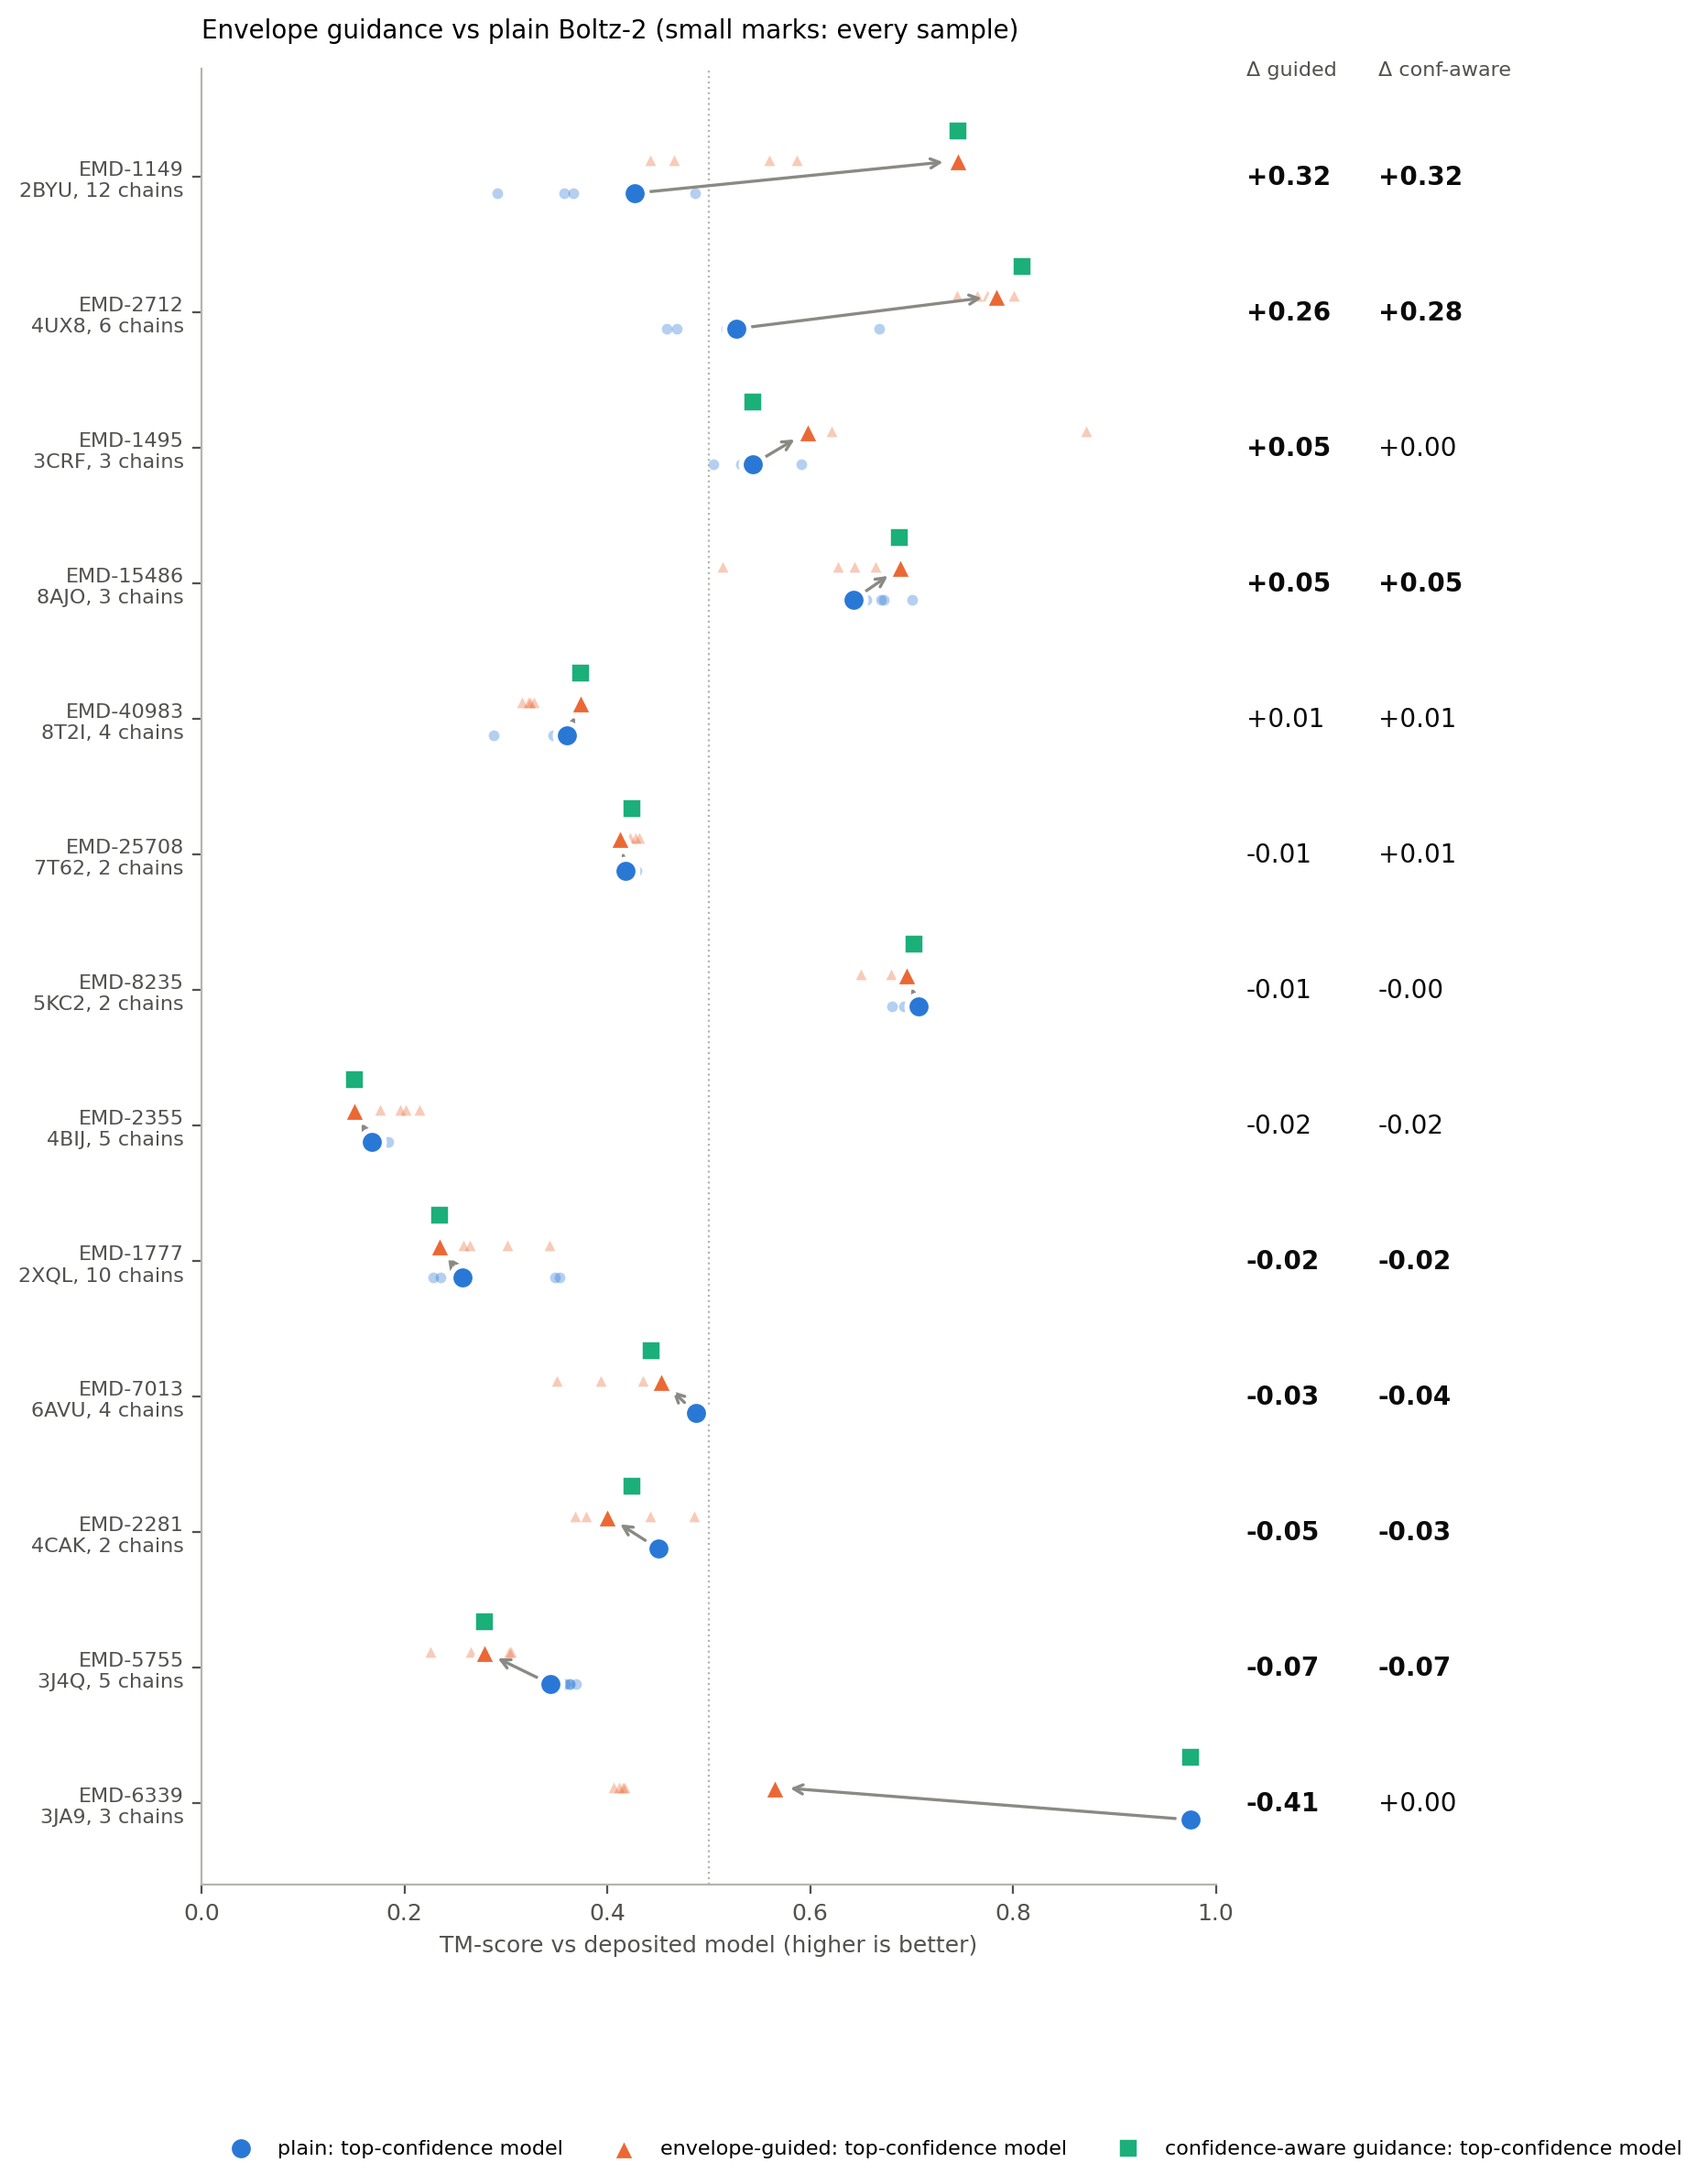

In [ ]:
_rows = []
for _e, _m in maps.items():
    _rows.append({"map": _e, "PDB": _m["pdb"], "residues": _m["tokens"], "chains": _m["chains"], "year": _m["year"],
                  "plain TM": _m[BASE]["tm_top_conf"], "guided TM": _m[GUIDED]["tm_top_conf"],
                  "Δ TM": _m["delta_tm_top_conf"], "plain best-of-N": _m[BASE]["tm_best"],
                  "guided best-of-N": _m[GUIDED]["tm_best"],
                  "plain vs guided TM": _m["cross_tm"],
                  "plain spread (min pairwise TM)": _m[BASE]["within_tm_min"]})
overview = pd.DataFrame(_rows).round(3)

# Showcase: the map where guidance helped most; if it helped nowhere, the map where the guided answer is most
# different from the plain one relative to the plain samples' own spread (a different conformation).
_helped = [m for m in maps.values() if m["delta_tm_top_conf"] > 0.02]
if _helped:
    showcase = max(_helped, key=lambda m: m["delta_tm_top_conf"])["emdb"]
    _why = "largest accuracy gain from the envelope"
else:
    showcase = min(maps.values(), key=lambda m: m["cross_tm"] - (m[BASE]["within_tm_min"] or 1.0))["emdb"]
    _why = "no map improved by more than 0.02 TM, so this is the map where guidance changed the answer most"
mo.vstack([mo.md(f"## All maps ({len(maps)})"), fig_overview(), mo.ui.table(overview, selection=None),
           mo.md(f"**Showcase pick: {showcase}** ({_why}). Pick another map below.")])

Confidence-aware guidance vs plain Boltz-2
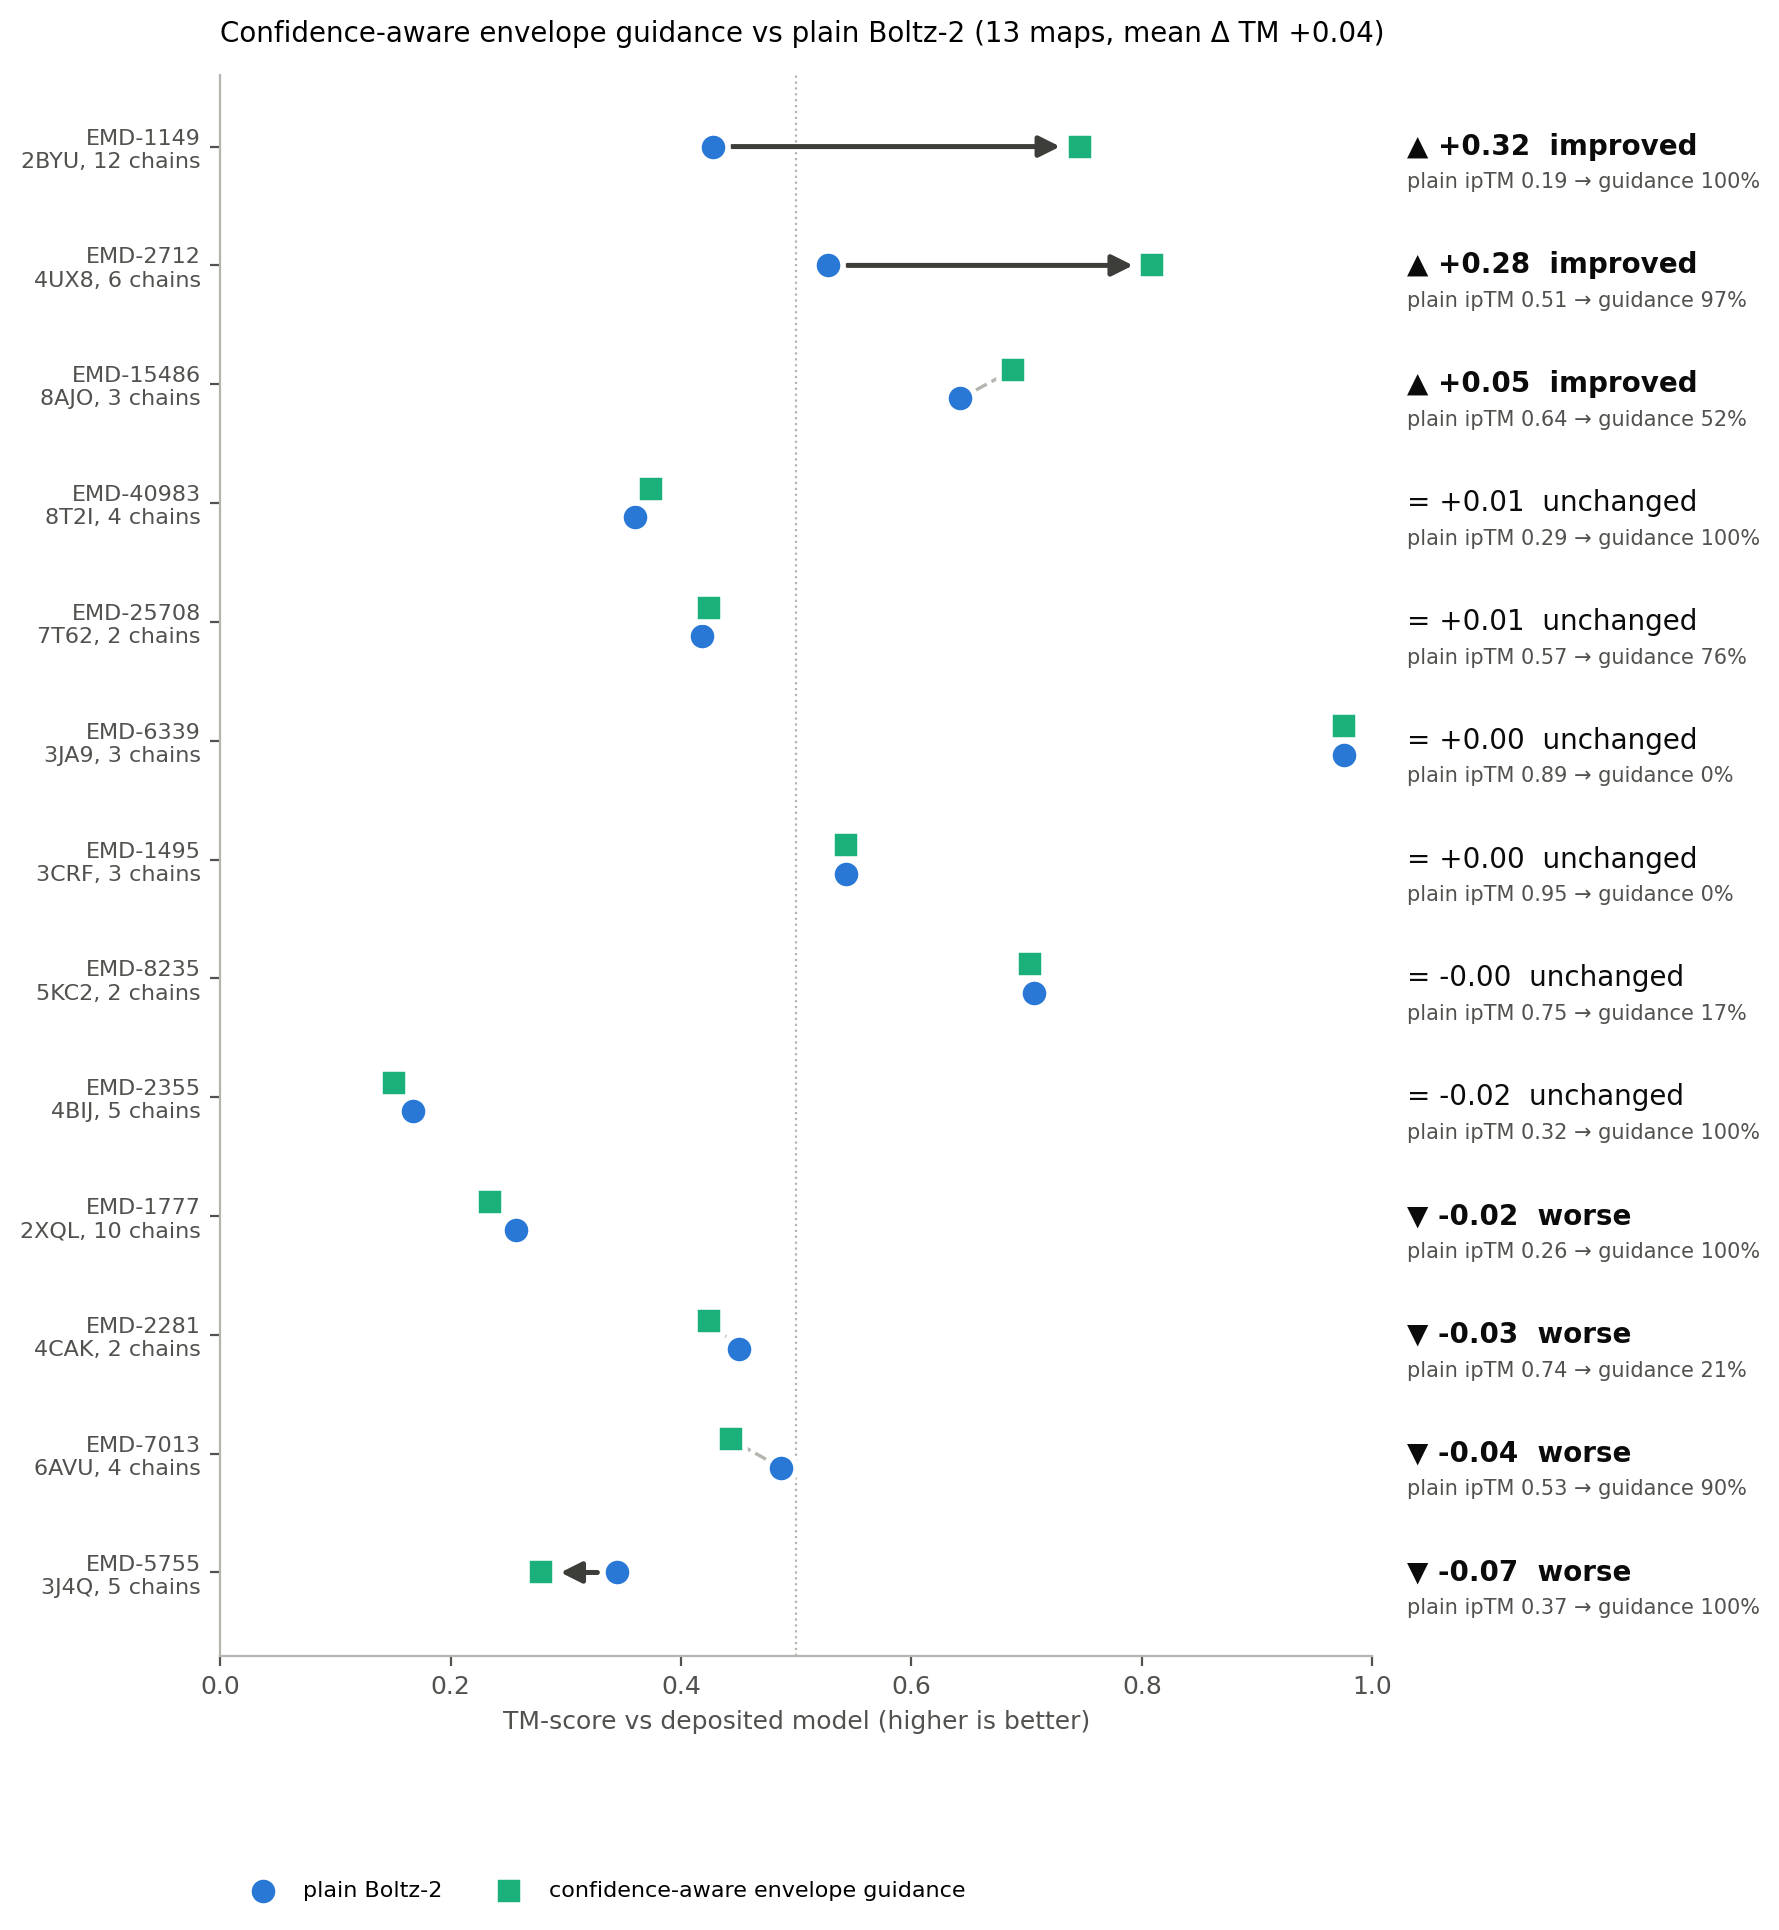

In [ ]:
_f = fig_adaptive()
mo.vstack([mo.md("## Confidence-aware guidance vs plain Boltz-2"), _f]) if _f is not None else mo.md("")

In [ ]:
# How should one use the envelope? Each strategy's final model per map, scored against the deposited model.
# The ipTM / envelope-CC picks choose between the plain and guided top-confidence models without the answer.
_rows = []
for _e, _m in sorted(maps.items()):
    _b, _g = _m[BASE], _m[GUIDED]
    _r = {"map": _e, "plain": _b["tm_top_conf"], "always guide": _g["tm_top_conf"]}
    if ADAPT and ADAPT in _m:
        _p = _m.get("adaptive_plan", {})
        _r["confidence-aware"] = _m[ADAPT]["tm_top_conf"]
        _r["plain ipTM → strength"] = (f"{_p['plain_iptm']:.2f} → {_p['strength']:.2f}" if _p else "")
    _r["pick by higher ipTM"] = (_g if _g["iptm_top"] > _b["iptm_top"] else _b)["tm_top_conf"]
    _r["pick by envelope fit"] = (_g if _g["cc_top_conf"] > _b["cc_top_conf"] else _b)["tm_top_conf"]
    _rows.append(_r)
strategies = pd.DataFrame(_rows)
_num = strategies.select_dtypes("number")
_mean = _num.mean().round(3)
_txt = ", ".join(f"{k} **{v:.2f}**" for k, v in _mean.items())
mo.vstack([
    mo.md("## Strategies: how to use the envelope\n"
          "TM-score of each strategy's final model. *Confidence-aware*: guidance strength set by the plain run's "
          "ipTM (full below 0.5, off above 0.8). *Pick by higher ipTM / envelope fit*: choose between the plain and "
          "always-guided models by that score."),
    mo.ui.table(strategies.round(3), selection=None),
    mo.md(f"Mean TM-score over {len(strategies)} maps: {_txt}."),
    mo.callout(mo.md(
        "Guided models get **lower ipTM on every map**, even where they are far more accurate, so ipTM cannot "
        "judge a guided structure; it is only used here to decide whether to guide at all. The ipTM cut-offs "
        "are the usual AlphaFold-Multimer bands, but only one map in this pilot is confident, so the rule needs "
        "more maps before it can be called validated."), kind="info"),
])

Strategies: how to use the envelope 
 TM-score of each strategy's final model. Confidence-aware : guidance strength set by the plain run's ipTM (full below 0.5, off above 0.8). Pick by higher ipTM / envelope fit : choose between the plain and always-guided models by that score. <marimo-table data-initial-value='[]' data-label='null' data-data='"[{\"map\":\"EMD-1149\",\"plain\":0.427,\"always guide\":0.746,\"confidence-aware\":0.746,\"plain ipTM \\u2192 strength\":\"0.19 \\u2192 1.00\",\"pick by higher ipTM\":0.427,\"pick by envelope fit\":0.746},{\"map\":\"EMD-1495\",\"plain\":0.544,\"always guide\":0.598,\"confidence-aware\":0.544,\"plain ipTM \\u2192 strength\":\"0.95 \\u2192 0.00\",\"pick by higher ipTM\":0.544,\"pick by envelope fit\":0.598},{\"map\":\"EMD-15486\",\"plain\":0.642,\"always guide\":0.689,\"confidence-aware\":0.688,\"plain ipTM \\u2192 strength\":\"0.64 \\u2192 0.52\",\"pick by higher ipTM\":0.642,\"pick by envelope fit\":0.689},{\"map\":\"EMD-1777\",\"plain\":0.257,\"always guide\":0.234,\"confidence-aware\":0.234,\"plain ipTM \\u2192 strength\":\"0.26 \\u2192 1.00\",\"pick by higher ipTM\":0.257,\"pick by envelope fit\":0.257},{\"map\":\"EMD-2281\",\"plain\":0.45,\"always guide\":0.4,\"confidence-aware\":0.424,\"plain ipTM \\u2192 strength\":\"0.74 \\u2192 0.21\",\"pick by higher ipTM\":0.45,\"pick by envelope fit\":0.4},{\"map\":\"EMD-2355\",\"plain\":0.168,\"always guide\":0.15,\"confidence-aware\":0.15,\"plain ipTM \\u2192 strength\":\"0.32 \\u2192 1.00\",\"pick by higher ipTM\":0.168,\"pick by envelope fit\":0.15},{\"map\":\"EMD-25708\",\"plain\":0.418,\"always guide\":0.413,\"confidence-aware\":0.425,\"plain ipTM \\u2192 strength\":\"0.57 \\u2192 0.76\",\"pick by higher ipTM\":0.418,\"pick by envelope fit\":0.413},{\"map\":\"EMD-2712\",\"plain\":0.528,\"always guide\":0.784,\"confidence-aware\":0.809,\"plain ipTM \\u2192 strength\":\"0.51 \\u2192 0.97\",\"pick by higher ipTM\":0.528,\"pick by envelope fit\":0.784},{\"map\":\"EMD-40983\",\"plain\":0.36,\"always guide\":0.374,\"confidence-aware\":0.374,\"plain ipTM \\u2192 strength\":\"0.29 \\u2192 1.00\",\"pick by higher ipTM\":0.36,\"pick by envelope fit\":0.374},{\"map\":\"EMD-5755\",\"plain\":0.344,\"always guide\":0.278,\"confidence-aware\":0.278,\"plain ipTM \\u2192 strength\":\"0.37 \\u2192 1.00\",\"pick by higher ipTM\":0.344,\"pick by envelope fit\":0.278}]"' data-total-rows='13' data-total-columns='7' data-max-columns='50' data-banner-text='""' data-pagination='true' data-page-size='10' data-field-types='[["map",["string","object"]],["plain",["number","float64"]],["always guide",["number","float64"]],["confidence-aware",["number","float64"]],["plain ipTM → strength",["string","object"]],["pick by higher ipTM",["number","float64"]],["pick by envelope fit",["number","float64"]]]' data-show-filters='true' data-show-download='true' data-show-search='true' data-show-column-summaries='true' data-show-data-types='true' data-show-page-size-selector='true' data-show-column-explorer='true' data-show-chart-builder='true' data-row-headers='[]' data-hidden-columns='[]' data-has-stable-row-id='false' data-lazy='false' data-preload='false'> Mean TM-score over 13 maps: plain 0.48 , always guide 0.49 , confidence-aware 0.52 , pick by higher ipTM 0.48 , pick by envelope fit 0.49 . <marimo-callout-output data-html='"\u003cspan class=\"markdown prose dark:prose-invert contents\"\u003e\u003cspan class=\"paragraph\"\u003eGuided models get \u003cstrong\u003elower ipTM on every map\u003c/strong\u003e, even where they are far more accurate, so ipTM cannot judge a guided structure; it is only used here to decide whether to guide at all. The ipTM cut-offs are the usual AlphaFold-Multimer bands, but only one map in this pilot is confident, so the rule needs more maps before it can be called validated.\u003c/span\u003e\u003c/span\u003e"' data-kind='"info"'>

In [ ]:
pick = mo.ui.dropdown(options=sorted(maps), value=showcase, label="Map")
pick

&lt;marimo-dropdown data-initial-value=&#x27;[&amp;quot;EMD-1149&amp;quot;]&#x27; data-label=&#x27;&amp;quot;&amp;#92;u003cspan class=&amp;#92;&amp;quot;markdown prose dark:prose-invert contents&amp;#92;&amp;quot;&amp;#92;u003e&amp;#92;u003cspan class=&amp;#92;&amp;quot;paragraph&amp;#92;&amp;quot;&amp;#92;u003eMap&amp;#92;u003c/span&amp;#92;u003e&amp;#92;u003c/span&amp;#92;u003e&amp;quot;&#x27; data-options=&#x27;[&amp;quot;EMD-1149&amp;quot;,&amp;quot;EMD-1495&amp;quot;,&amp;quot;EMD-15486&amp;quot;,&amp;quot;EMD-1777&amp;quot;,&amp;quot;EMD-2281&amp;quot;,&amp;quot;EMD-2355&amp;quot;,&amp;quot;EMD-25708&amp;quot;,&amp;quot;EMD-2712&amp;quot;,&amp;quot;EMD-40983&amp;quot;,&amp;quot;EMD-5755&amp;quot;,&amp;quot;EMD-6339&amp;quot;,&amp;quot;EMD-7013&amp;quot;,&amp;quot;EMD-8235&amp;quot;]&#x27; data-allow-select-none=&#x27;false&#x27; data-searchable=&#x27;false&#x27; data-full-width=&#x27;false&#x27; data-disabled=&#x27;false&#x27;&gt;&lt;/marimo-dropdown&gt;

In [ ]:
m = maps[pick.value]
b, g = m[BASE], m[GUIDED]
_d = m["delta_tm_top_conf"]
_extra = []
if ADAPT and ADAPT in m:
    _p = m.get("adaptive_plan", {})
    _extra = [mo.stat(f"{m[ADAPT]['tm_top_conf']:.2f}", label="Confidence-aware TM-score",
                      caption=(f"plain ipTM {_p['plain_iptm']:.2f} → strength {_p['strength']:.2f}" if _p else ""))]
mo.hstack([
    mo.stat(f"{b['tm_top_conf']:.2f}", label="Plain TM-score", caption=f"RMSD {b['rmsd_top_conf']:.1f} Å"),
    mo.stat(f"{g['tm_top_conf']:.2f}", label="Guided TM-score", caption=f"RMSD {g['rmsd_top_conf']:.1f} Å",
            direction="increase" if _d > 0 else "decrease" if _d < 0 else None),
    mo.stat(f"{_d:+.2f}", label="Change from the envelope", caption="guided − plain, top-confidence models"),
    mo.stat(f"{b['cc_top_conf']:.2f} → {g['cc_top_conf']:.2f}", label="Envelope fit (CC)",
            caption=f"deposited model: {m['deposited_env_cc']:.2f}"),
] + _extra, widths="equal")

In [ ]:
_d, _cross = m["delta_tm_top_conf"], m["cross_tm"]
_spread = min(x for x in [b["within_tm_min"], g["within_tm_min"]] if x is not None) \
    if any(x is not None for x in [b["within_tm_min"], g["within_tm_min"]]) else None
if _d > 0.02:
    _acc = f"The envelope **improved** accuracy: TM {b['tm_top_conf']:.2f} → {g['tm_top_conf']:.2f} ({_d:+.2f})."
elif _d < -0.02:
    _acc = f"The envelope **reduced** accuracy here: TM {b['tm_top_conf']:.2f} → {g['tm_top_conf']:.2f} ({_d:+.2f})."
else:
    _acc = f"Accuracy was **about the same** (TM {b['tm_top_conf']:.2f} vs {g['tm_top_conf']:.2f})."
if _spread is None:
    _conf = f"Plain vs guided top models: TM {_cross:.2f} to each other (only one sample per mode, so no spread to compare)."
elif _cross < _spread - 0.02:
    _conf = (f"The guided answer is a **different arrangement**: the two top models agree only to TM {_cross:.2f}, "
             f"while samples within a mode agree to at least {_spread:.2f}. That difference is beyond sampling noise.")
else:
    _conf = (f"The guided and plain answers are **similar** (TM {_cross:.2f} to each other; samples within a mode "
             f"agree to at least {_spread:.2f}).")
_sel = (f"Picking the plain sample that best fits the envelope instead of Boltz's top-confidence one gives "
        f"TM {b['tm_top_cc']:.2f} (vs {b['tm_top_conf']:.2f}).")
mo.callout(mo.md(f"""
**What this map shows**

- {_acc}
- {_conf}
- Envelope fit of the top model: {b['cc_top_conf']:.2f} plain → {g['cc_top_conf']:.2f} guided (deposited model: {m['deposited_env_cc']:.2f}).
- {_sel}

Caveats: a handful of maps with {b['n']} samples per mode is a pilot, not proof. Deposited model from {m['year']};
structures from before Boltz-2's training cutoff may be partly memorised, which inflates plain-Boltz scores.
"""), kind="success" if _d > 0.02 else "neutral")

<marimo-callout-output data-html='"\u003cspan class=\"markdown prose dark:prose-invert contents\"\u003e\u003cspan class=\"paragraph\"\u003e\u003cstrong\u003eWhat this map shows\u003c/strong\u003e\u003c/span\u003e\n\u003cul\u003e\n\u003cli\u003eThe envelope \u003cstrong\u003eimproved\u003c/strong\u003e accuracy: TM 0.43 → 0.75 (+0.32).\u003c/li\u003e\n\u003cli\u003eThe guided answer is a \u003cstrong\u003edifferent arrangement\u003c/strong\u003e: the two top models agree only to TM 0.38, while samples within a mode agree to at least 0.41. That difference is beyond sampling noise.\u003c/li\u003e\n\u003cli\u003eEnvelope fit of the top model: 0.53 plain → 0.91 guided (deposited model: 0.90).\u003c/li\u003e\n\u003cli\u003ePicking the plain sample that best fits the envelope instead of Boltz's top-confidence one gives TM 0.49 (vs 0.43).\u003c/li\u003e\n\u003c/ul\u003e\n\u003cspan class=\"paragraph\"\u003eCaveats: a handful of maps with 5 samples per mode is a pilot, not proof. Deposited model from 2006;\nstructures from before Boltz-2's training cutoff may be partly memorised, which inflates plain-Boltz scores.\u003c/span\u003e\u003c/span\u003e"' data-kind='"success"'>

Structures: plain vs envelope-guided
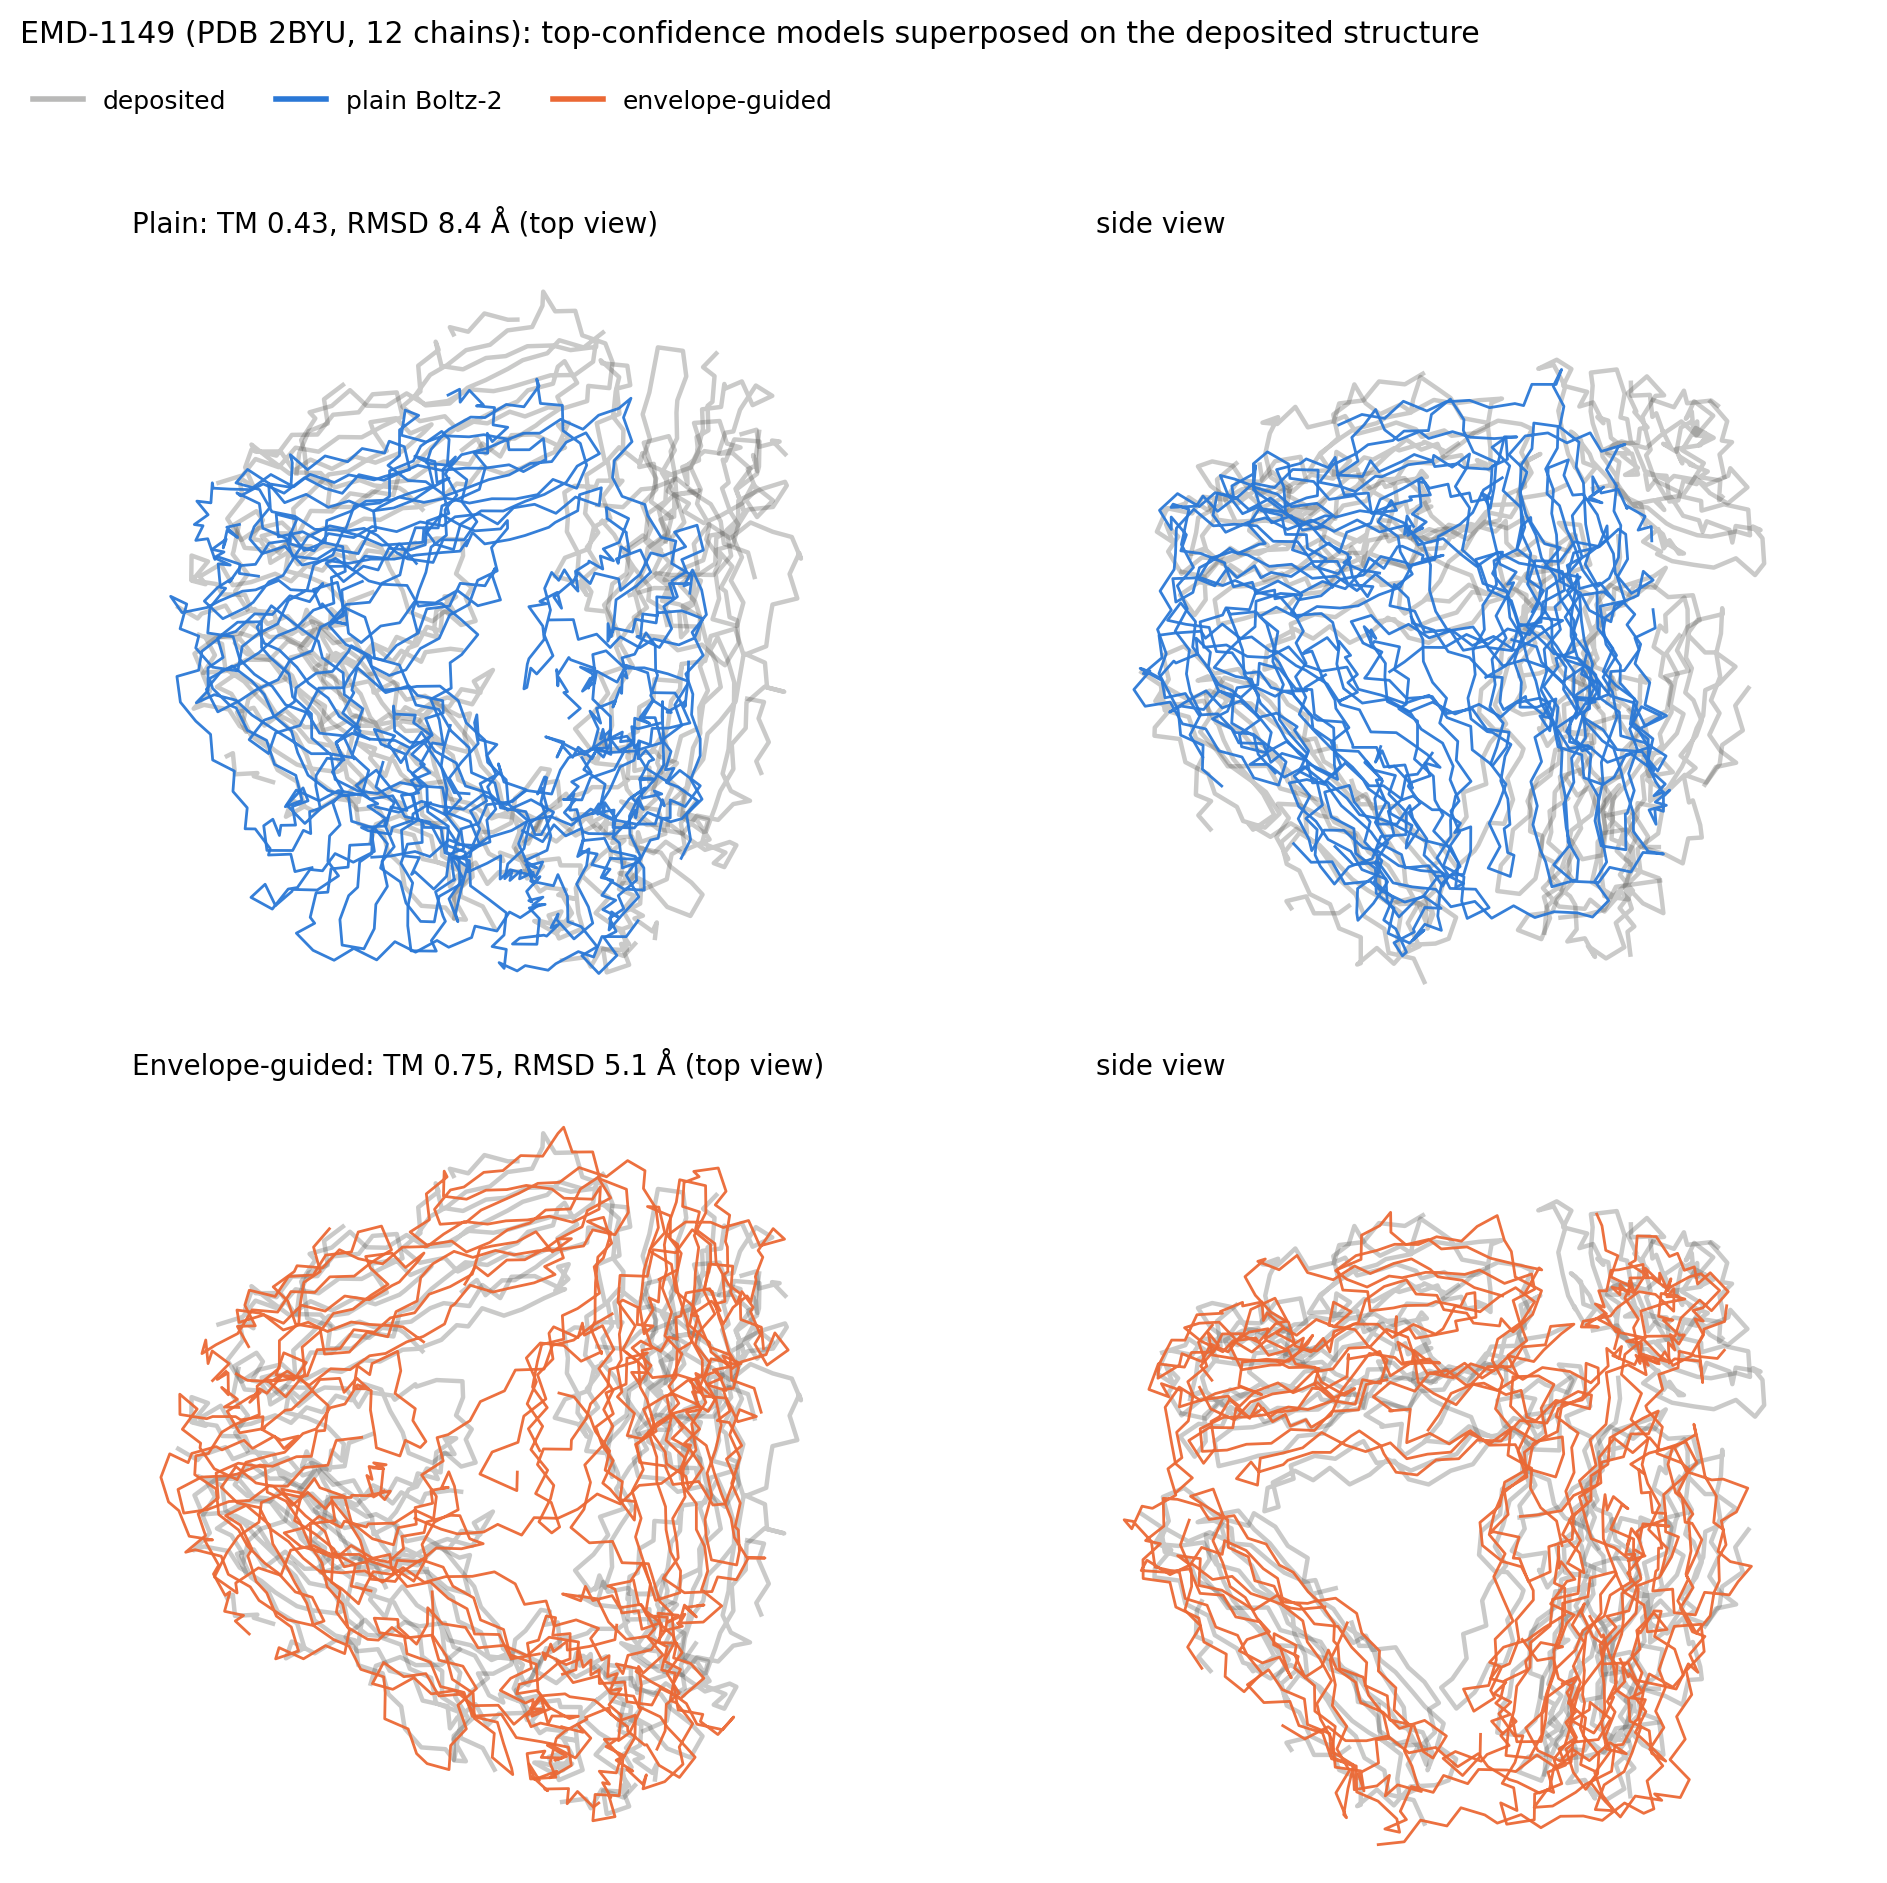

In [ ]:
mo.vstack([mo.md("## Structures: plain vs envelope-guided"), fig_structures(pick.value)])

Fit to the envelope
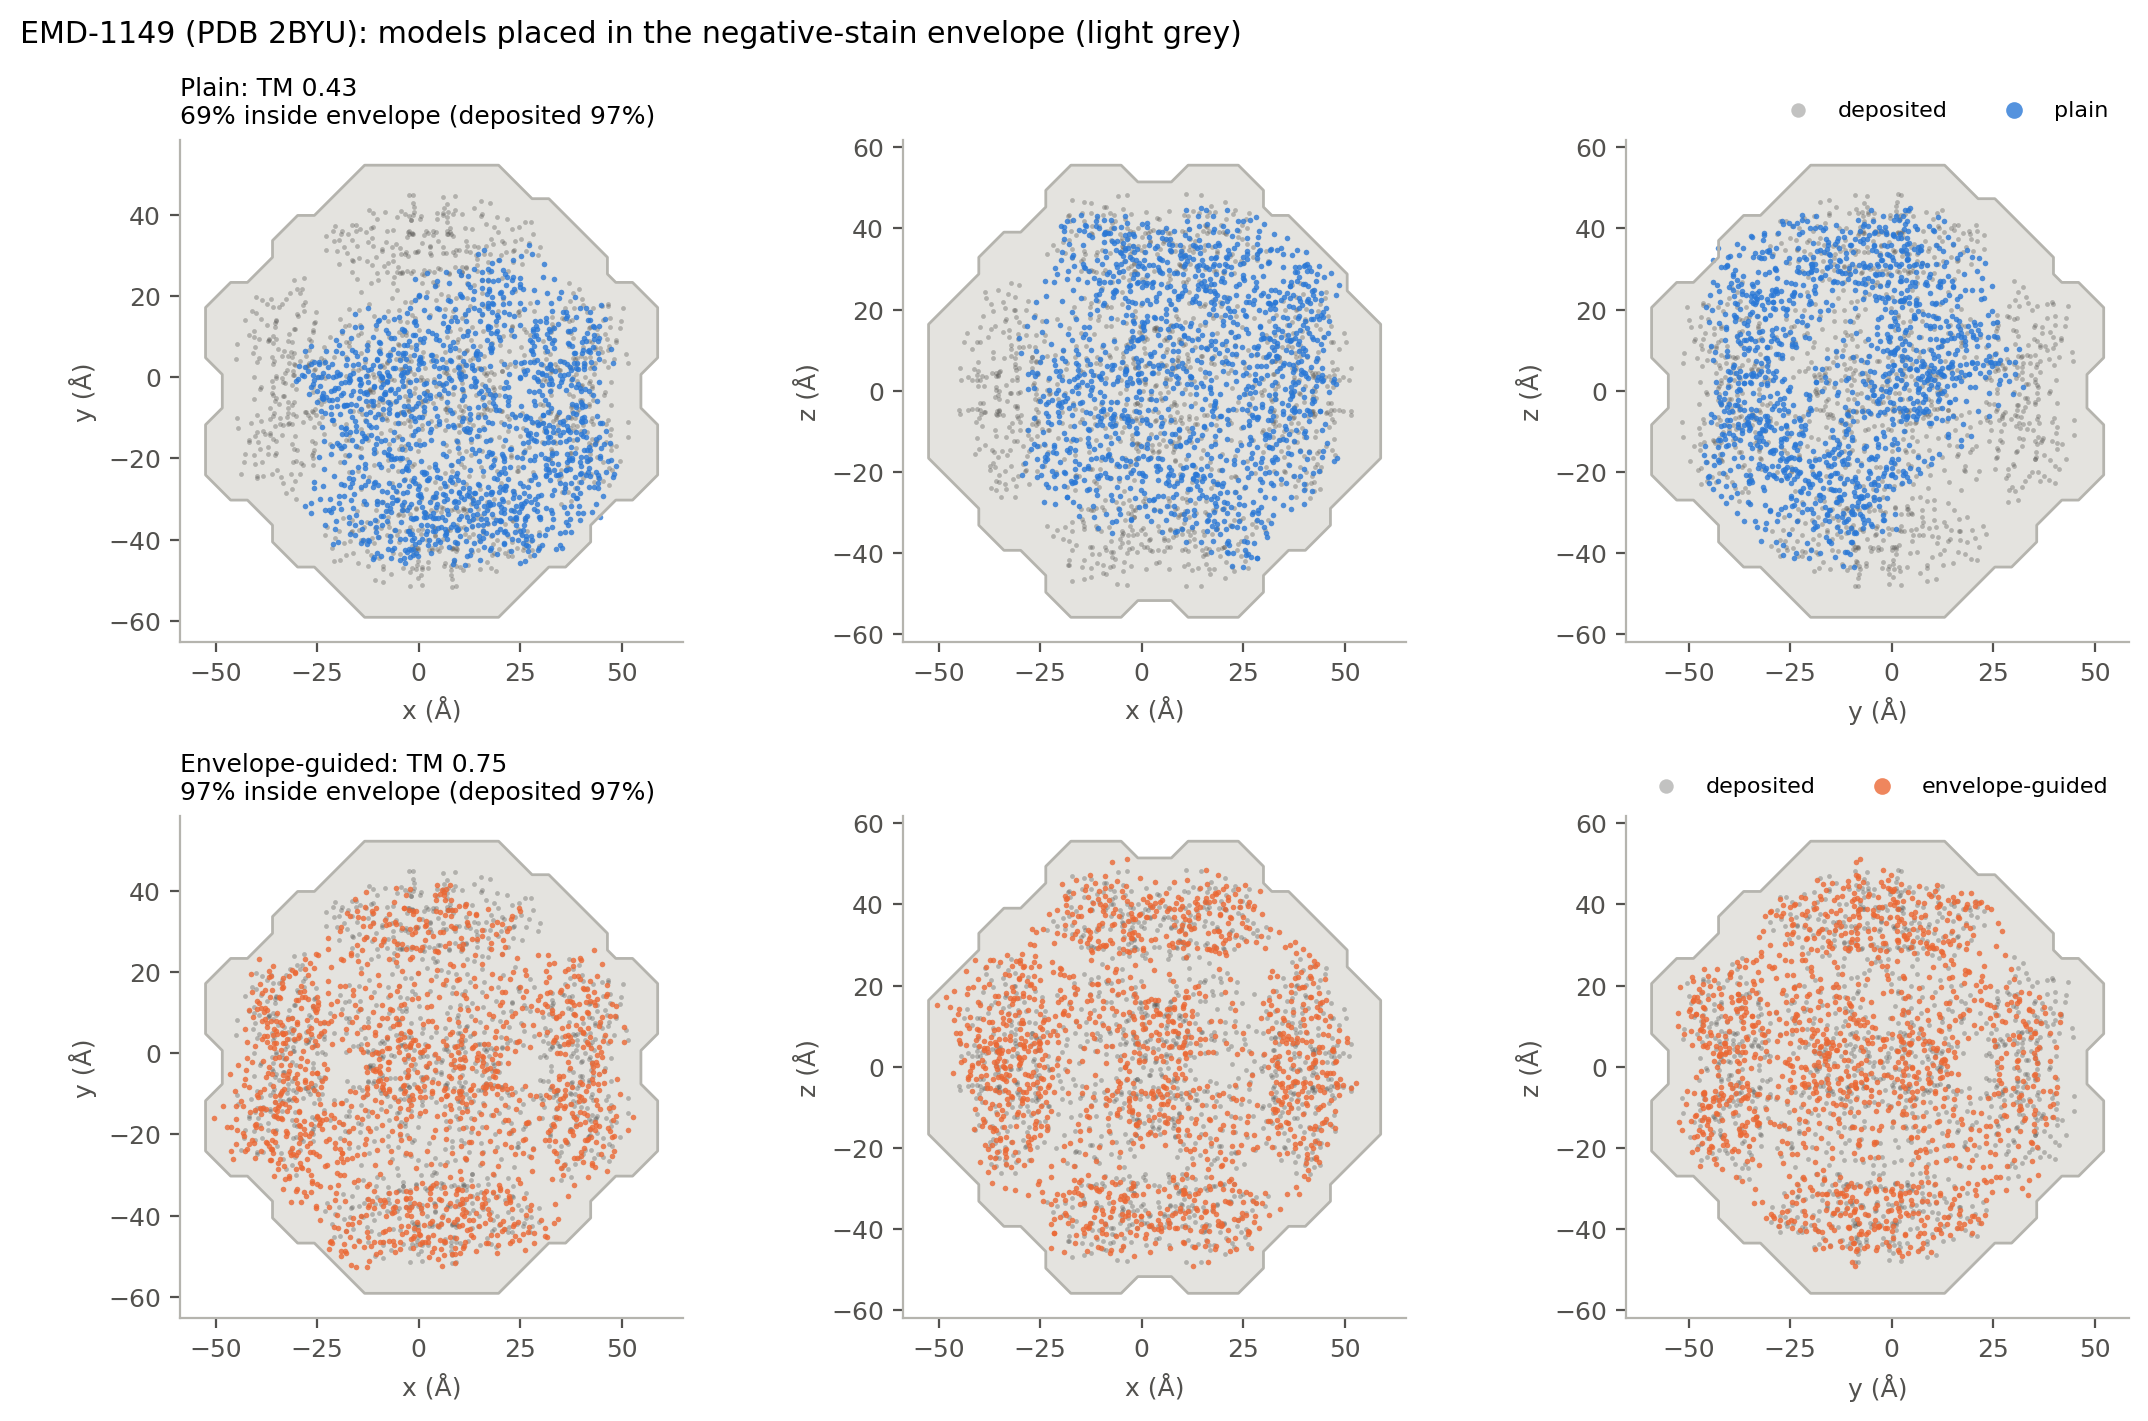

In [ ]:
mo.vstack([mo.md("## Fit to the envelope"), fig_envelope(pick.value)])

Every sample
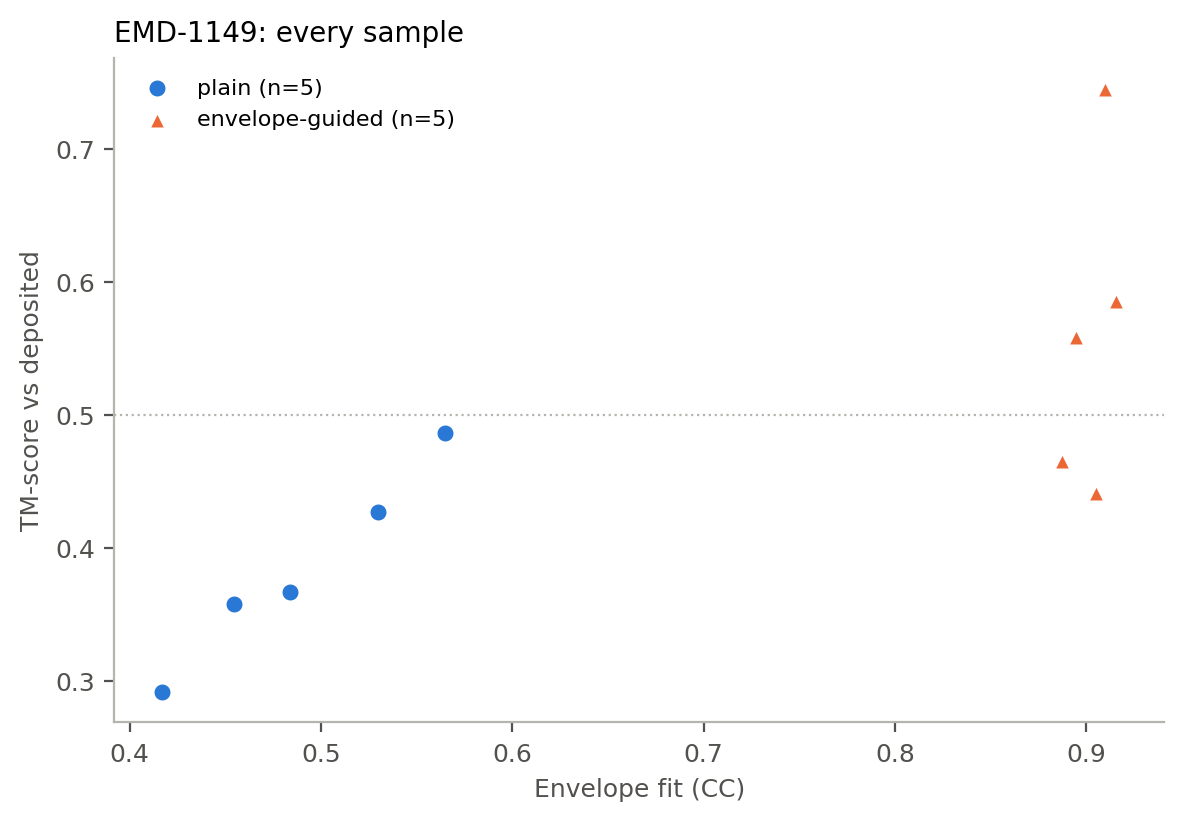

In [ ]:
mo.vstack([mo.md("## Every sample"), fig_samples(pick.value)])

Guidance at work
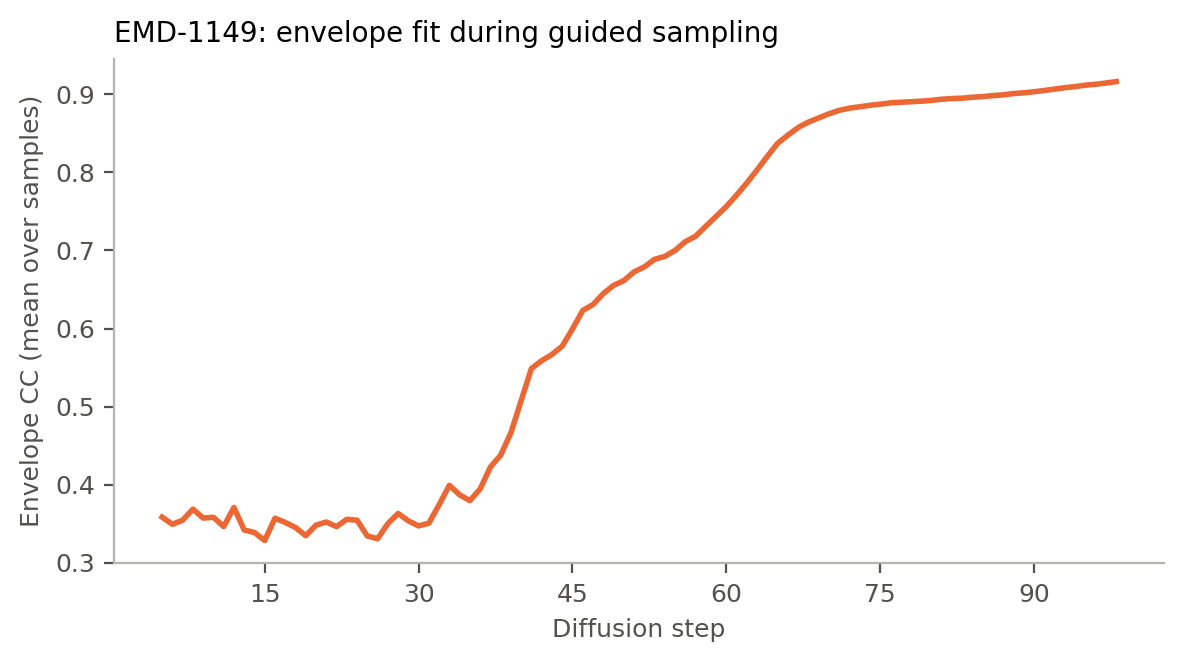

In [ ]:
_p = os.path.join(RES, "analysis", pick.value, "guide_log.json")
if os.path.exists(_p):
    _log = json.load(open(_p))["log"]
    _fig, _a = plt.subplots(figsize=(6, 3.4))
    _a.plot([e["step"] for e in _log], [np.mean(e["cc_after"]) for e in _log], color=C_GUIDED, lw=2)
    _a.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    _a.set_xlabel("Diffusion step"); _a.set_ylabel("Envelope CC (mean over samples)")
    _a.set_title(f"{pick.value}: envelope fit during guided sampling", loc="left", fontsize=10)
    _fig.tight_layout()
    _out = mo.vstack([mo.md("## Guidance at work"), _fig])
else:
    _out = mo.md("_No guidance trace for this map._")
_out

In [ ]:
show = mo.ui.multiselect(options=["deposited", "plain", "envelope-guided"],
                         value=["deposited", "plain", "envelope-guided"], label="Show")
mo.vstack([mo.md("## 3D: top models superposed on the deposited structure"), show])

3D: top models superposed on the deposited structure

In [ ]:
try:
    import py3Dmol
except ImportError:
    py3Dmol = None
if py3Dmol is None:
    _out = mo.md("Install `py3Dmol` for the 3D view (`pip install py3Dmol`). The superposed files are in "
                 f"`modal_results/analysis/{pick.value}/` for ChimeraX or PyMOL.")
else:
    _view = py3Dmol.view(width=880, height=540)
    _files = {"deposited": ("deposited.cif", C_DEP), "plain": (f"{BASE}_top.cif", C_PLAIN),
              "envelope-guided": (f"{GUIDED}_top.cif", C_GUIDED)}
    for _i, _name in enumerate(n for n in _files if n in show.value):
        _f, _col = _files[_name]
        _view.addModel(open(os.path.join(RES, "analysis", pick.value, _f)).read(), "cif")
        _view.setStyle({"model": _i}, {"cartoon": {"color": _col, "opacity": 0.55 if _name == "deposited" else 1.0}})
    _view.zoomTo()
    # an iframe runs the page's own <script> tags (3Dmol.js); mo.Html does not
    _out = mo.vstack([mo.iframe(_view._make_html(), height="560px"),
                      mo.md("Grey = deposited, blue = plain, orange = envelope-guided. Drag to rotate.")])
_out

<iframe srcdoc='<div id="3dmolviewer_17926791576395059" style="position: relative; width: 880px; height: 540px;">
 <p id="3dmolwarning_17926791576395059" style="background-color:#ffcccc;color:black">3Dmol.js failed to load for some reason. Please check your browser console for error messages.<br></p>
 </div>
<script>

var loadScriptAsync = function(uri){
 return new Promise((resolve, reject) => {
 //this is to ignore the existence of requirejs amd
 var savedexports, savedmodule;
 if (typeof exports !== 'undefined') savedexports = exports;
 else exports = {}
 if (typeof module !== 'undefined') savedmodule = module;
 else module = {}

 var tag = document.createElement('script');
 tag.src = uri;
 tag.async = true;
 tag.onload = () => {
 exports = savedexports;
 module = savedmodule;
 resolve();
 };
 var firstScriptTag = document.getElementsByTagName('script')[0];
 firstScriptTag.parentNode.insertBefore(tag, firstScriptTag);
});
};

if(typeof $3Dmolpromise === 'undefined') {
$3Dmolpromise = null;
 $3Dmolpromise = loadScriptAsync('https://cdn.jsdelivr.net/npm/3dmol@2.5.5/build/3Dmol-min.js');
}

var viewer_17926791576395059 = null;
var warn = document.getElementById("3dmolwarning_17926791576395059");
if(warn) {
 warn.parentNode.removeChild(warn);
}
$3Dmolpromise.then(function() {
viewer_17926791576395059 = $3Dmol.createViewer(document.getElementById("3dmolviewer_17926791576395059"),{backgroundColor:"white"});
viewer_17926791576395059.zoomTo();
	viewer_17926791576395059.addModel("data_XXXX\n# \nloop_\n_audit_author.name \n_audit_author.pdbx_ordinal \n\"Kennaway, C.K.\" 1 \n\"Benesch, J.L.P.\" 2 \n\"Gohlke, U.\" 3 \n\"Wang, L.\" 4 \n\"Robinson, C.V.\" 5 \n\"Orlova, E.V.\" 6 \n\"Saibil, H.R.\" 7 \n\"Keep, N.H.\" 8 \n# \n_struct.entry_id XXXX \n_struct.title \"Negative stain EM reconstruction of M.tuberculosis Acr1(Hsp 16.3) fitted with wheat sHSP dimer\" \n_struct.pdbx_model_details ? \n_struct.pdbx_CASP_flag ? \n_struct.pdbx_model_type_details ? \n# \n_struct_keywords.entry_id XXXX \n_struct_keywords.pdbx_keywords CHAPERONE \n_struct_keywords.text \"SMALL HEAT SHOCK PROTEIN, ALPHA-CRYSTALLIN, CHAPERONE\" \n# \n_exptl.entry_id XXXX \n_exptl.method \"ELECTRON MICROSCOPY\" \n_exptl.crystals_number ? \n# \n_citation.id primary \n_citation.title \"Dodecameric Structure of the Small Heat Shock Protein Acr1 from Mycobacterium Tuberculosis.\" \n_citation.journal_abbrev J.Biol.Chem. \n_citation.journal_volume 280 \n_citation.page_first 33419 \n_citation.page_last ? \n_citation.year 2005 \n_citation.journal_id_ASTM JBCHA3 \n_citation.country US \n_citation.journal_id_ISSN 0021-9258 \n_citation.journal_id_CSD 0071 \n_citation.book_publisher ? \n_citation.pdbx_database_id_PubMed 16046399 \n_citation.pdbx_database_id_DOI 10.1074/JBC.M504263200 \n# \nloop_\n_citation_author.citation_id \n_citation_author.name \n_citation_author.ordinal \n_citation_author.identifier_ORCID \nprimary \"Kennaway, C.K.\" 1 ? \nprimary \"Benesch, J.L.P.\" 2 ? \nprimary \"Gohlke, U.\" 3 ? \nprimary \"Wang, L.\" 4 ? \nprimary \"Robinson, C.V.\" 5 ? \nprimary \"Orlova, E.V.\" 6 ? \nprimary \"Saibil, H.R.\" 7 ? \nprimary \"Keep, N.H.\" 8 ? \n# \n_entity_poly.entity_id 1 \n_entity_poly.type \"polypeptide(L)\" \n_entity_poly.nstd_linkage no \n_entity_poly.nstd_monomer no \n_entity_poly.pdbx_seq_one_letter_code \n;NARMDWKETPEAHVFKADLPGVKKEEVKVEVEDGNVLVVSGERTKEKEDKNDKWHRVERSSGKFVRRFRLLEDAKVEEVK\nAGLENGVLTVTVPKAEVKKPEVKAIQISG\n;\n_entity_poly.pdbx_seq_one_letter_code_can \n;NARMDWKETPEAHVFKADLPGVKKEEVKVEVEDGNVLVVSGERTKEKEDKNDKWHRVERSSGKFVRRFRLLEDAKVEEVK\nAGLENGVLTVTVPKAEVKKPEVKAIQISG\n;\n_entity_poly.pdbx_strand_id A,B,C,D,E,F,G,H,I,J,K,L \n_entity_poly.pdbx_target_identifier ? \n# \nloop_\n_entity_poly_seq.entity_id \n_entity_poly_seq.num \n_entity_poly_seq.mon_id \n_entity_poly_seq.hetero \n1 1 ASN n \n1 2 ALA n \n1 3 ARG n \n1 4 MET n \n1 5 ASP n \n1 6 TRP n \n1 7 LYS n \n1 8 GLU n \n1 9 THR n \n1 10 PRO n \n1 11 GLU n \n1 12 ALA n \n1 13 HIS n \n1 14 VAL n \n1 15 PHE n \n1 1

In [ ]:
# Save every figure (all maps) as PNG for slides and papers.
os.makedirs(FIGS, exist_ok=True)
_saved = []
_adapt = fig_adaptive()
for _name, _fig in [("overview", fig_overview())] + ([("confidence_aware_vs_plain", _adapt)] if _adapt else []) + \
        [(f"{_e}_{_k}", _f(_e)) for _e in sorted(maps)
         for _k, _f in [("structures", fig_structures), ("envelope", fig_envelope), ("samples", fig_samples)]]:
    _path = os.path.join(FIGS, f"{_name}.png")
    _fig.savefig(_path, dpi=200, bbox_inches="tight", facecolor="white")
    plt.close(_fig)
    _saved.append(f"`{os.path.basename(_path)}`")
mo.md(f"**Saved {len(_saved)} figures to** `{FIGS}`: " + ", ".join(_saved))

C:\Users\sohil\AppData\Local\Temp\marimo_33256\__marimo__cell_bkHC_.py:141: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, axs = plt.subplots(2, 2, figsize=(10, 9.4))


**Saved 41 figures to** `C:\Users\sohil\Documents\Envelope-guided Boltz pilot\EMDB_negative_stain_maps\modal_results\showcase_figures`: `overview.png`, `confidence_aware_vs_plain.png`, `EMD-1149_structures.png`, `EMD-1149_envelope.png`, `EMD-1149_samples.png`, `EMD-1495_structures.png`, `EMD-1495_envelope.png`, `EMD-1495_samples.png`, `EMD-15486_structures.png`, `EMD-15486_envelope.png`, `EMD-15486_samples.png`, `EMD-1777_structures.png`, `EMD-1777_envelope.png`, `EMD-1777_samples.png`, `EMD-2281_structures.png`, `EMD-2281_envelope.png`, `EMD-2281_samples.png`, `EMD-2355_structures.png`, `EMD-2355_envelope.png`, `EMD-2355_samples.png`, `EMD-25708_structures.png`, `EMD-25708_envelope.png`, `EMD-25708_samples.png`, `EMD-2712_structures.png`, `EMD-2712_envelope.png`, `EMD-2712_samples.png`, `EMD-40983_structures.png`, `EMD-40983_envelope.png`, `EMD-40983_samples.png`, `EMD-5755_structures.png`, `EMD-5755_envelope.png`, `EMD-5755_samples.png`, `EMD-6339_structures.png`, `EMD-6339_envelope.png`, `EMD-6339_samples.png`, `EMD-7013_structures.png`, `EMD-7013_envelope.png`, `EMD-7013_samples.png`, `EMD-8235_structures.png`, `EMD-8235_envelope.png`, `EMD-8235_samples.png`